In [148]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

from scipy.io import loadmat
import h5py


- distribution 
- stats entre trucs
- volcano plots 
- pour chacun et pour tous ? 
- pour les 104 
- pour le moment j'ai load que pour un fichier, mais généraliser à tous, et faire un truc pratique 

- stats vs optimaux : les 9 paramètres fittés : faire plusieurs tests statistiques pour chaque (pour comparer), et les plot (tableau ?)
- 

## **Data Loading**

In [149]:
data = loadmat("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_ENS_Fit/Comportement_FRINT_ENS_num5_LL1311_M5_VBMC")
out = data["out_vbmc"][0,0]

In [150]:
# all results from fitting for the 104 subjects from online task (online rotation condition)
filepaths_rotations = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/Lucas*M5*VBMC.mat")
outs_rotations = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_rotations]

# all data from fitting for the behavioral passations at ENS (in lab condition)
filepaths_ENS = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_ENS_Fit/Comportement*M5*VBMC.mat")
outs_ENS = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_ENS]

# all results from fitting for the 100 subjects from online task (online weight condition)
filepaths_weights = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FWINT_Fit/Lucas*M5*VBMC.mat")
outs_weights = [loadmat(f)["out_vbmc"][0,0] for f in filepaths_weights]

## **Exploring SINGLE Matlab Dataset**

In [151]:
print(out.dtype.names)

('s_sen', 'g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 's_fac', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep', 'p_lap', 'pnam', 'pmap', 'pavg', 'fitalgo', 'version', 'tfit', 'nsmp', 'nres', 'nobs', 'nfit', 'vp', 'elbo', 'elbo_sd', 'xnam', 'xmap', 'xavg', 'xstd', 'xcov', 'xmed', 'xqrt', 'xc95', 'xnam_all', 'xhat_all', 'options', 'output', 'tss', 'ess', 'zang_f', 'zabs_f', 'xcon_f', 'zang_u', 'zabs_u', 'xcon_u')


In [152]:
# to get the name of a parameter :
print([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

# to get the value of a parameter :
print(out["xavg"].squeeze())

# to get one item from the file : 
print(out["g_sen"].item())

# to get the list of items of a parameter : 
print(out["pmap"][0].item())

['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']
[ 1.00994195  0.48299202  0.1472296  -0.57869694  0.77457611  0.84202605
  0.57207059  0.7689688   0.14214459]
1.0099419456461458
(array([[0]], dtype=uint8), array([[0.98453029]]), array([[0.48638325]]), array([[0.11800041]]), array([[-0.57526005]]), array([[0]], dtype=uint8), array([[0.66121676]]), array([[0.75842828]]), array([[0.51260302]]), array([[0.73041806]]), array([[0.14322807]]), array([[0]], dtype=uint8))


## **Info and Dataframes**

In [153]:
tfit = out["tfit"][0].item()
print("total fitting time =", tfit)
nfit = out["nfit"][0].item()
print("number of fitted parameters =", nfit)
xnam = out["xnam"][0]
print("the name of fitted parameters are :", [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

total fitting time = 494.84331504166664
number of fitted parameters = 9
the name of fitted parameters are : ['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']


In [154]:
parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], columns =  ["value"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], range(12)) : 
    parameters.loc[column] = out[num].item()

parameters["mod"] = np.squeeze(out["pmap"][0].item())
parameters["average"] = np.squeeze(out["pavg"][0].item())

parameters


,value,mod,average
s_sen,0,0.000000,0.000000
g_sen,1.009942,0.984530,1.009942
s_rot,0.482992,0.486383,0.482992
d_rot_p,0.14723,0.118000,0.147230
d_rot_m,-0.578697,-0.575260,-0.578697
s_fac,0,0.000000,0.000000
w_fac_p,0.774576,0.661217,0.774576
w_fac_m,0.842026,0.758428,0.842026
s_int,0.572071,0.512603,0.572071
l_int,0.768969,0.730418,0.768969


In [155]:
fitted_parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], columns =  ["average", "mod", "std","median", "Q1", "Q3", "c95_left", "c95_right"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], range(12)) : 
    fitted_parameters["average"] = out["xavg"].squeeze()
    fitted_parameters["mod"] = out["xmap"].squeeze()
    fitted_parameters["std"] = out["xstd"].squeeze()
    fitted_parameters["median"] = out["xmed"].squeeze()
    fitted_parameters["Q1"] = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"] = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"] = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

fitted_parameters

,average,mod,std,median,Q1,Q3,c95_left,c95_right
g_sen,1.009942,0.984530,0.206463,1.011329,0.871316,1.149842,0.601987,1.411063
s_rot,0.482992,0.486383,0.042885,0.482983,0.454270,0.511489,0.398719,0.568141
d_rot_p,0.147230,0.118000,0.074938,0.145851,0.096590,0.196763,0.003176,0.297952
d_rot_m,-0.578697,-0.575260,0.094425,-0.580528,-0.643731,-0.516050,-0.757529,-0.388419
w_fac_p,0.774576,0.661217,0.230542,0.744660,0.609537,0.906791,0.411767,1.308175
w_fac_m,0.842026,0.758428,0.312829,0.797936,0.615138,1.021745,0.360808,1.571889
s_int,0.572071,0.512603,0.104400,0.562848,0.502200,0.630770,0.390610,0.811904
l_int,0.768969,0.730418,0.203574,0.753437,0.624514,0.896134,0.416324,1.211503
s_rep,0.142145,0.143228,0.043666,0.137245,0.111055,0.167723,0.071015,0.241946


## **All subjects in one place**

In [156]:
tot_fit_time = []
for i in range(len(outs_rotations)) : 
    out = outs_rotations[i]
    tfit = out["tfit"][0].item()
    tot_fit_time.append(tfit)
print(f"the average total fitting time for the rotation group is {np.mean(tot_fit_time):.3f}", "\n. All the fitting times are in the variable called 'tot_fit_time'")

tot_fit_time_FWINT = []
for i in range(len(outs_weights)) : 
    out = outs_rotations[i]
    tfit = out["tfit"][0].item()
    tot_fit_time_FWINT.append(tfit)
print(f"the average total fitting time for the weight group is {np.mean(tot_fit_time_FWINT):.3f}", "\n. All the fitting times are in the variable called 'tot_fit_time_FWINT'")

the average total fitting time for the rotation group is 1310.028 
. All the fitting times are in the variable called 'tot_fit_time'
the average total fitting time for the weight group is 1322.453 
. All the fitting times are in the variable called 'tot_fit_time_FWINT'


online condition

In [157]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_rotations):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)

    row_d_rot_p["average"] -= np.deg2rad(45)
    row_d_rot_p["mod"]     -= np.deg2rad(45)
    row_d_rot_m["average"] -= np.deg2rad(-45)
    row_d_rot_m["mod"]     -= np.deg2rad(-45)   

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_rotations = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

In [158]:
fitted_params_rotations["d_rot_p"]

,average,mod,std,median,Q1,Q3,c95_left,c95_right
0,-0.235769,-0.226799,0.067924,0.550567,0.504372,0.595775,0.413913,0.680513
1,0.092899,0.101480,0.052215,0.879715,0.844062,0.914063,0.771762,0.976676
2,-0.133210,-0.136609,0.041589,0.652472,0.624342,0.680319,0.569833,0.732865
3,-0.318962,-0.313227,0.164827,0.470821,0.357289,0.580122,0.131169,0.777088
4,0.095927,0.086468,0.059224,0.882703,0.842110,0.922057,0.761337,0.993355
...,...,...,...,...,...,...,...,...
99,0.008312,0.006228,0.048927,0.794782,0.761603,0.827125,0.694388,0.886488
100,-0.197607,-0.238616,0.113049,0.586455,0.512893,0.660747,0.368353,0.819857
101,0.108979,0.220168,0.133956,0.904406,0.810005,0.989396,0.604938,1.127561
102,-0.045088,-0.054542,0.075517,0.743131,0.691342,0.792484,0.584021,0.880092


weights condition

In [159]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_weights):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)
    
    row_d_rot_p["average"] -= np.deg2rad(45)
    row_d_rot_p["mod"]     -= np.deg2rad(45)
    row_d_rot_m["average"] -= np.deg2rad(-45)
    row_d_rot_m["mod"]     -= np.deg2rad(-45)

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_weights = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

in lab condition

In [160]:
all_g_sen = None
all_s_rot = None
all_d_rot_p = None
all_d_rot_m = None
all_s_fac = None
all_w_fac_p = None
all_w_fac_m = None
all_s_rep = None
all_s_int = None
all_p_lap = None
all_l_int = None

for i, out in enumerate(outs_ENS):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    row_g_sen   = fitted_parameters.loc[["g_sen"]].reset_index(drop=True)
    row_s_rot   = fitted_parameters.loc[["s_rot"]].reset_index(drop=True)
    row_d_rot_p = fitted_parameters.loc[["d_rot_p"]].reset_index(drop=True)
    row_d_rot_m = fitted_parameters.loc[["d_rot_m"]].reset_index(drop=True)
    row_w_fac_p = fitted_parameters.loc[["w_fac_p"]].reset_index(drop=True)
    row_w_fac_m = fitted_parameters.loc[["w_fac_m"]].reset_index(drop=True)
    row_s_rep   = fitted_parameters.loc[["s_rep"]].reset_index(drop=True)
    row_s_int   = fitted_parameters.loc[["s_int"]].reset_index(drop=True)
    row_l_int   = fitted_parameters.loc[["l_int"]].reset_index(drop=True)
    
    row_d_rot_p["average"] -= np.deg2rad(45)
    row_d_rot_p["mod"]     -= np.deg2rad(45)
    row_d_rot_m["average"] -= np.deg2rad(-45)
    row_d_rot_m["mod"]     -= np.deg2rad(-45)

    all_g_sen   = row_g_sen   if all_g_sen is None   else pd.concat([all_g_sen, row_g_sen], ignore_index=True)
    all_s_rot   = row_s_rot   if all_s_rot is None   else pd.concat([all_s_rot, row_s_rot], ignore_index=True)
    all_d_rot_p = row_d_rot_p if all_d_rot_p is None else pd.concat([all_d_rot_p, row_d_rot_p], ignore_index=True)
    all_d_rot_m = row_d_rot_m if all_d_rot_m is None else pd.concat([all_d_rot_m, row_d_rot_m], ignore_index=True)
    all_w_fac_p = row_w_fac_p if all_w_fac_p is None else pd.concat([all_w_fac_p, row_w_fac_p], ignore_index=True)
    all_w_fac_m = row_w_fac_m if all_w_fac_m is None else pd.concat([all_w_fac_m, row_w_fac_m], ignore_index=True)
    all_s_rep   = row_s_rep   if all_s_rep is None   else pd.concat([all_s_rep, row_s_rep], ignore_index=True)
    all_s_int   = row_s_int   if all_s_int is None   else pd.concat([all_s_int, row_s_int], ignore_index=True)
    all_l_int   = row_l_int   if all_l_int is None   else pd.concat([all_l_int, row_l_int], ignore_index=True)

fitted_params_inlab = {
    "g_sen": all_g_sen,
    "s_rot": all_s_rot,
    "d_rot_p": all_d_rot_p,
    "d_rot_m": all_d_rot_m,
    "w_fac_p": all_w_fac_p,
    "w_fac_m": all_w_fac_m,
    "s_rep": all_s_rep,
    "s_int": all_s_int,
    "l_int": all_l_int,
}

## **Reach variables**

To get the dataframe for one parameter (with all metrics)

    fitted_params_rotations["param"]
- "g_sen"
- "s_rot"
- "d_rot_p"
- "d_rot_m"
- "w_fac_p"
- "w_fac_m"
- "s_rep"
- "s_int"
- "l_int"

In [161]:
fitted_params_rotations["g_sen"]

,average,mod,std,median,Q1,Q3,c95_left,c95_right
0,0.559325,0.561647,0.231216,0.556360,0.403249,0.711244,0.113478,1.026418
1,0.726039,0.724175,0.165407,0.726975,0.615484,0.837601,0.399016,1.048259
2,0.876875,0.897226,0.163573,0.877540,0.767541,0.987566,0.553438,1.194705
3,1.327599,1.447364,0.271291,1.325507,1.146471,1.507244,0.801438,1.867459
4,0.891952,0.855419,0.183624,0.892937,0.768461,1.016619,0.530243,1.249188
...,...,...,...,...,...,...,...,...
99,0.564106,0.533723,0.112909,0.562727,0.487815,0.639348,0.345250,0.788874
100,0.252385,0.237787,0.169607,0.252268,0.139602,0.364897,-0.081303,0.586897
101,0.353316,0.399984,0.322647,0.352955,0.137895,0.568713,-0.280467,0.988677
102,-0.502325,-0.567325,0.210991,-0.505415,-0.646016,-0.362162,-0.906916,-0.079125


## **plotting data**

In [162]:
color_mapping = {
    "sensory" : ["g_sen"], # yellow
    "integration" : ["s_int", "l_int"], # blue
    "transformation" : ["s_rot", "d_rot_p", "d_rot_m", "w_fac_p", "w_fac_m"], # light pink
    "response" : ["s_rep"] # dark pink/violet
}

category_colors = {
    "sensory": "#FFA724D5",        
    "integration": "#4CC3FFD5",   
    "transformation": "#F02C46C1", 
    "response": "#882BBACC"        
}

def get_category(param):
    for cat, params in color_mapping.items():
        if param in params:
            return cat
    return None

volin plot pour seulement les données comportementales en ligne 

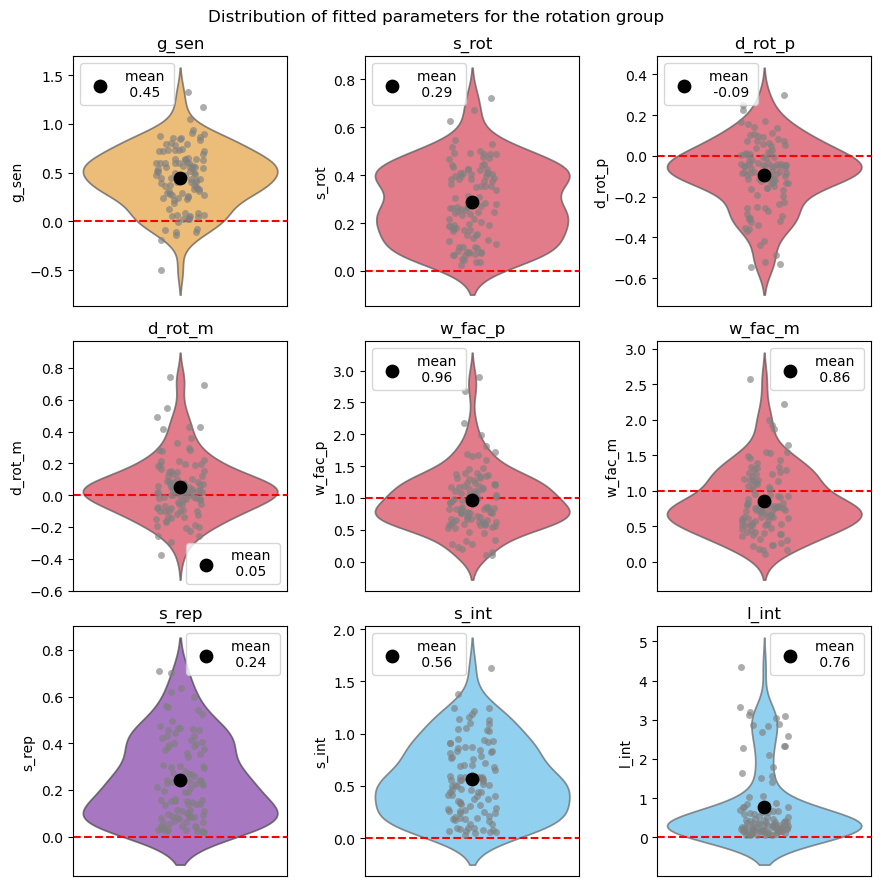

In [163]:
plt.fig, axes = plt.subplots(3, 3, figsize=(9, 9))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": 0,
    "d_rot_m": 0,
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]

    category = get_category(param)
    base_color = category_colors[category]

    # point_color = sns.light_palette(base_color, n_colors=3)[1]
    # line_color = sns.dark_palette(base_color, n_colors=3)[2]


    sns.violinplot(y=data, inner=None, color=base_color, ax=ax, alpha = 0.7)
    sns.stripplot(y=data, color="grey", alpha=0.65, ax=ax)

    mean = data.mean()
    ax.scatter(0, mean, color="black", s=80, zorder=3, label = f'mean \n {mean:.2f}')

    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="red", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.legend()

    plt.title(f"{param}")

plt.suptitle("Distribution of fitted parameters for the rotation group")
plt.tight_layout()
plt.show()

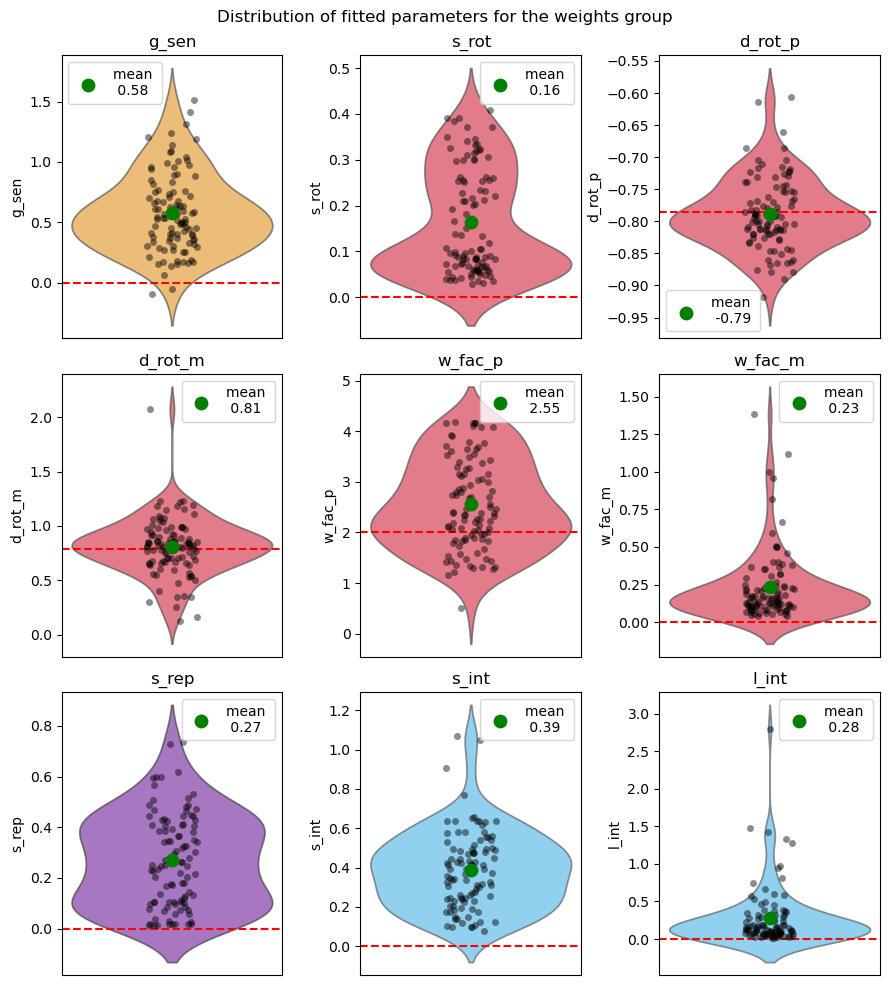

In [164]:
plt.fig, axes = plt.subplots(3, 3, figsize=(9, 10))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": -np.deg2rad(45),
    "d_rot_m": np.deg2rad(45),
    "w_fac_p": 2,
    "w_fac_m": 0,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_weights.keys())):

    data = fitted_params_weights[param]["average"]

    category = get_category(param)
    base_color = category_colors[category]

    # point_color = sns.light_palette(base_color, n_colors=3)[1]
    # line_color = sns.dark_palette(base_color, n_colors=3)[2]


    sns.violinplot(y=data, inner=None, color=base_color, ax=ax, alpha = 0.7)
    sns.stripplot(y=data, color="black", alpha=0.45, ax=ax)

    mean = data.mean()
    ax.scatter(0, mean, color="green", s=80, zorder=3, label = f'mean \n {mean:.2f}')

    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="red", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.legend()

    plt.title(f"{param}")

plt.suptitle("Distribution of fitted parameters for the weights group")
plt.tight_layout()
plt.show()

### différences entre average et le mod

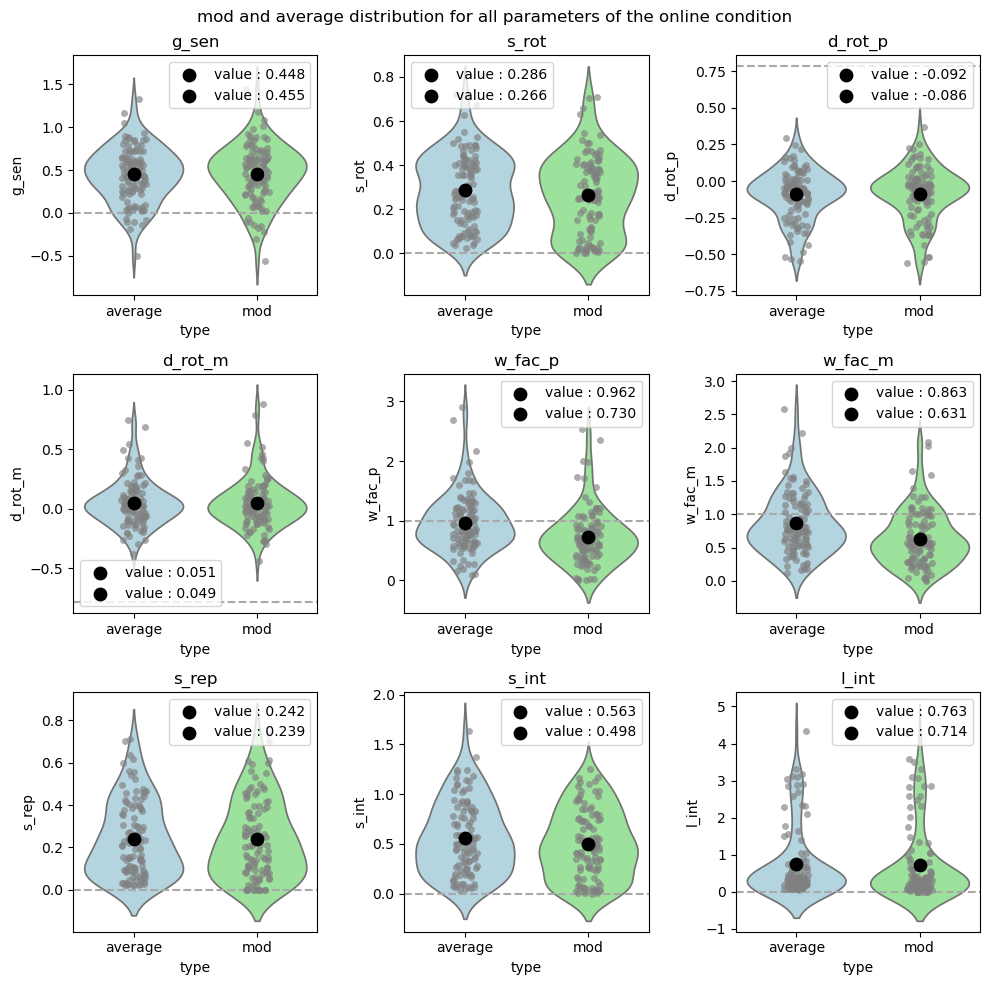

,g_sen,s_rot,d_rot_p,d_rot_m,w_fac_p,w_fac_m,s_rep,s_int,l_int
stat,2248.000000,1.116000e+03,2328.000000,2446.000000,1.280000e+02,6.000000e+01,1959.000000,4.560000e+02,9.710000e+02
p,0.118045,1.659782e-07,0.192367,0.357073,3.234080e-17,4.788695e-18,0.012412,1.654042e-13,1.169606e-08
mean_avg,0.448377,2.860681e-01,-0.092165,0.051431,9.620284e-01,8.626615e-01,0.242040,5.628424e-01,7.626855e-01
mean_mod,0.454875,2.659019e-01,-0.086432,0.048882,7.303036e-01,6.313495e-01,0.238864,4.979903e-01,7.143595e-01


In [165]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": np.deg2rad(45),
    "d_rot_m": np.deg2rad(-45),
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2),
        "type": ["average"]*len(data) + ["mod"]*len(data2)
    })

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=["lightblue", "lightgreen"], ax=ax, legend = False)

    sns.stripplot(data=df_plot, x="type", y="value",
                color="grey", alpha=0.65, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="black", s=80, zorder=3, label = f'value : {m:.3f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param)
    ax.set_xticks([0,1])
    ax.set_xticklabels(["average", "mod"])
    ax.legend()

plt.suptitle("mod and average distribution for all parameters of the online condition")
plt.tight_layout()
plt.legend()
plt.savefig("violin plot avg vs mod.pdf")
plt.show()


from scipy.stats import wilcoxon
from scipy.stats import ttest_rel

results = {}

for param in fitted_params_rotations.keys():
    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    # stat, p = ttest_rel(data, data2)

    stat, p = wilcoxon(data, data2)

    results[param] = {
        "stat": stat,
        "p": p,
        "mean_avg": data.mean(),
        "mean_mod": data2.mean()
    }

pd.DataFrame(results)

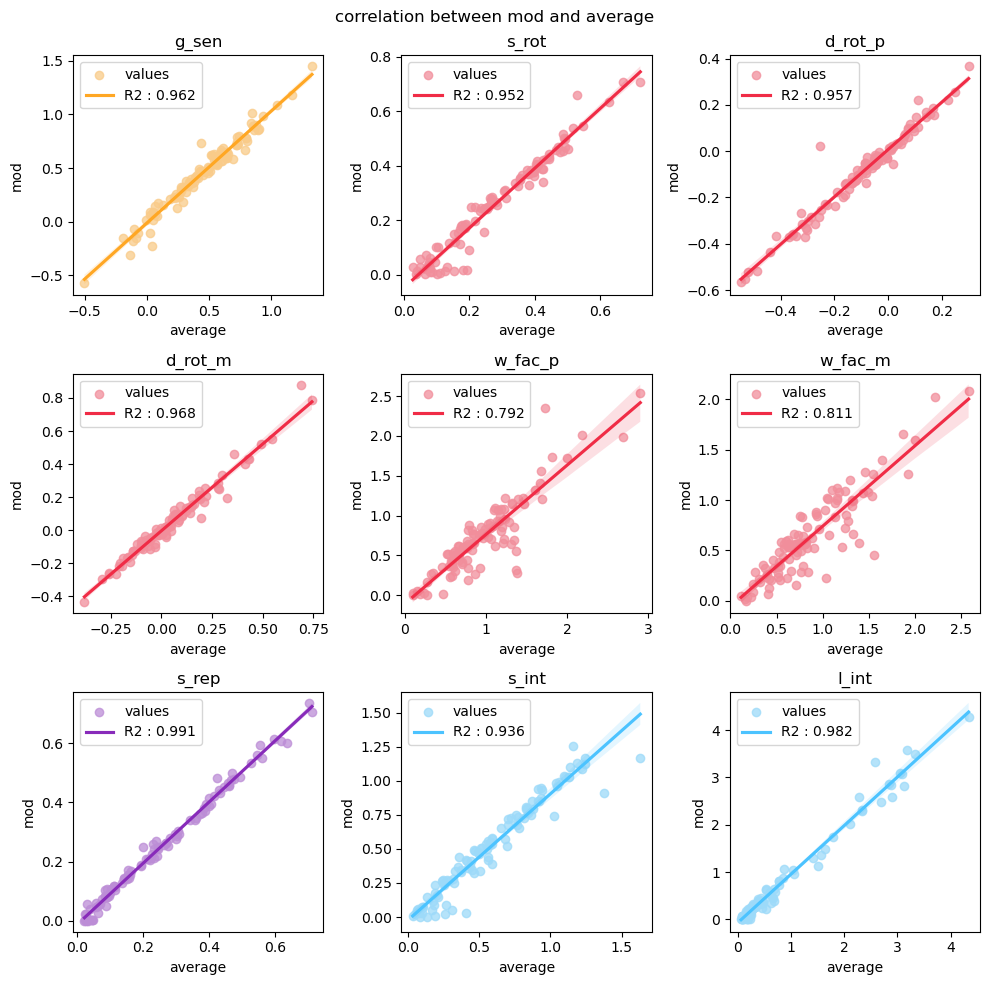

In [166]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    x = fitted_params_rotations[param]["average"]
    y = fitted_params_rotations[param]["mod"]
    
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r2 = r_value**2

    category = get_category(param)
    base_color = category_colors[category]

    point_color = sns.light_palette(base_color, n_colors=3)[1],
    line_color = sns.light_palette(base_color, n_colors=3)[2]

    sns.regplot(x="average", y="mod", data = fitted_params_rotations[param], label = "values", scatter_kws={'alpha':0.75, 'color':point_color}, line_kws={"color": line_color, "label" : f"R2 : {r2:.3f}", "alpha" : 1 }, ax=ax)

    ax.legend()
    ax.set_title(param)
    
plt.suptitle("correlation between mod and average")
plt.tight_layout()
plt.legend()
plt.show()

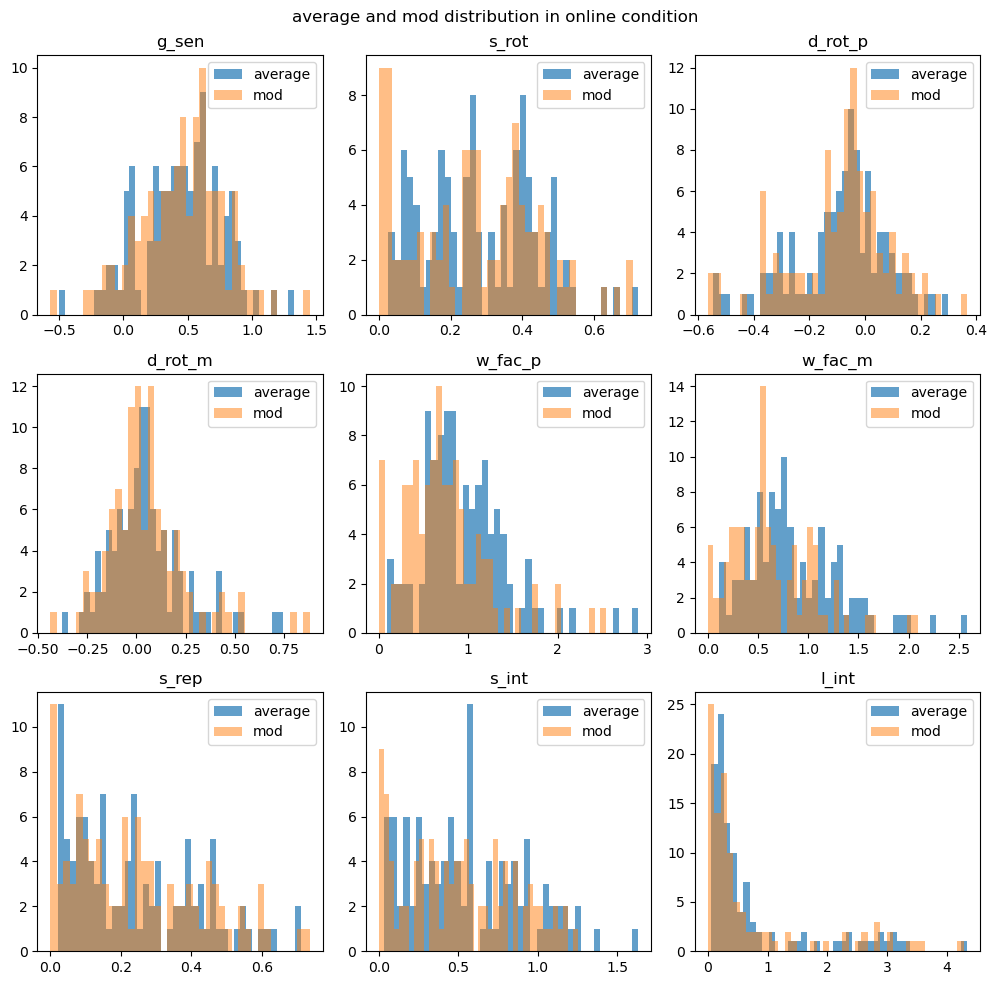

In [167]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for ax, (name, df) in zip(axes.flatten(), fitted_params_rotations.items()):
    
    ax.hist(df["average"], bins=40, alpha=0.7, label="average")
    ax.hist(df["mod"], bins=40, alpha=0.5, label="mod")
    
    ax.set_title(name)
    ax.legend()

plt.suptitle("average and mod distribution in online condition")
plt.tight_layout()
plt.show()

ONLINE VS IN LAB

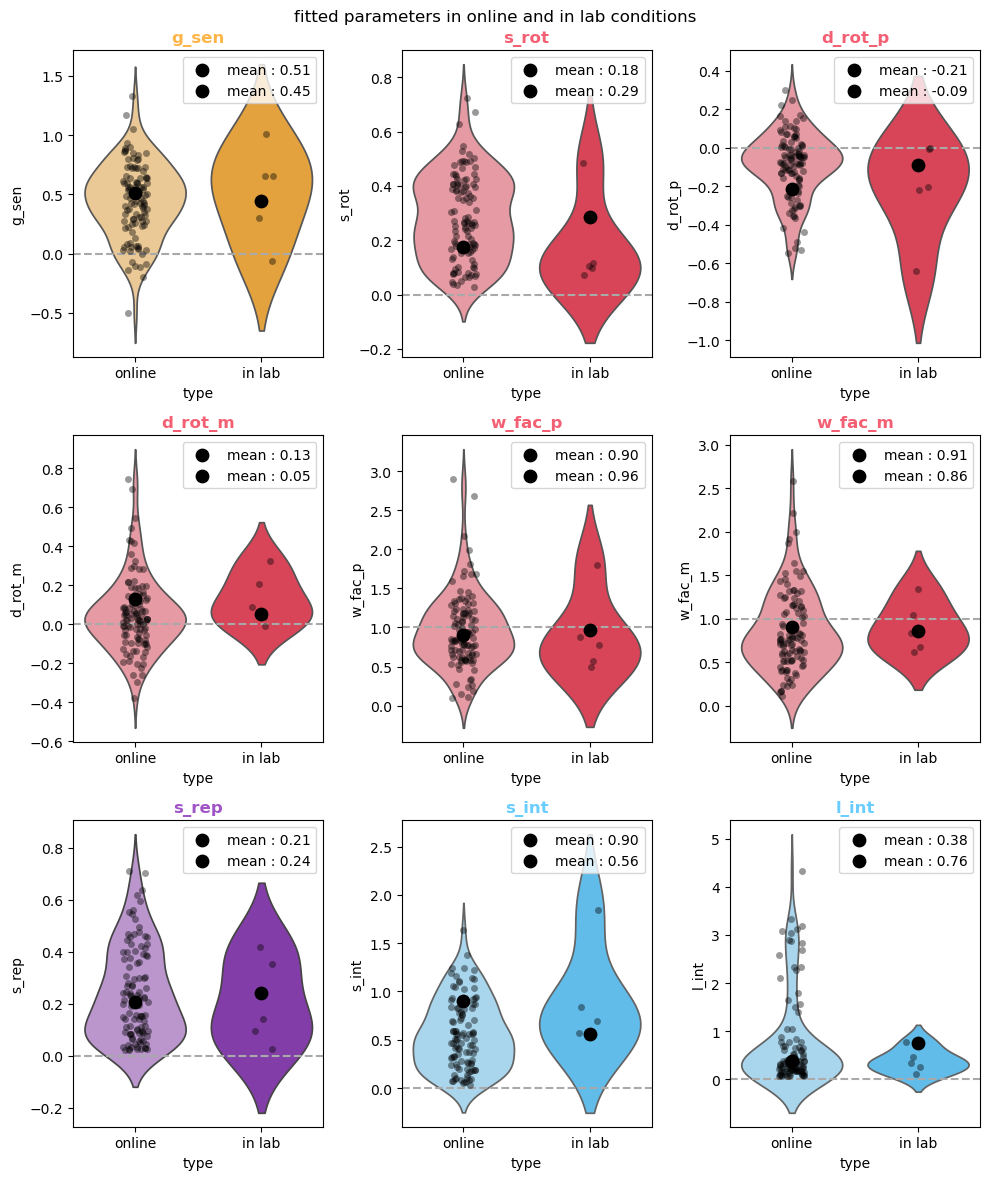

,g_sen,s_rot,d_rot_p,d_rot_m,w_fac_p,w_fac_m,s_rep,s_int,l_int
stat,2248.000000,1.116000e+03,2328.000000,2446.000000,1.280000e+02,6.000000e+01,1959.000000,4.560000e+02,9.710000e+02
p,0.118045,1.659782e-07,0.192367,0.357073,3.234080e-17,4.788695e-18,0.012412,1.654042e-13,1.169606e-08
mean_avg,0.448377,2.860681e-01,-0.092165,0.051431,9.620284e-01,8.626615e-01,0.242040,5.628424e-01,7.626855e-01
mean_mod,0.454875,2.659019e-01,-0.086432,0.048882,7.303036e-01,6.313495e-01,0.238864,4.979903e-01,7.143595e-01


In [168]:
fig, axes = plt.subplots(3, 3, figsize=(10, 12))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": 0,
    "d_rot_m": 0,
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2),
        "type": ["online"]*len(data) + ["in lab"]*len(data2)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "online": sns.light_palette(base_color, n_colors=3)[1],
        "in lab": sns.light_palette(base_color, n_colors=3)[2]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="black", s=80, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1])
    ax.set_xticklabels(["online", "in lab"])
    ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()
plt.legend()
plt.savefig("violin plots online vs in lab.pdf")
plt.show()

from scipy.stats import wilcoxon
from scipy.stats import ttest_rel

results = {}

for param in fitted_params_rotations.keys():
    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_rotations[param]["mod"]

    # stat, p = ttest_rel(data, data2)

    stat, p = wilcoxon(data, data2)

    results[param] = {
        "stat": stat,
        "p": p,
        "mean_avg": data.mean(),
        "mean_mod": data2.mean()
    }

pd.DataFrame(results)

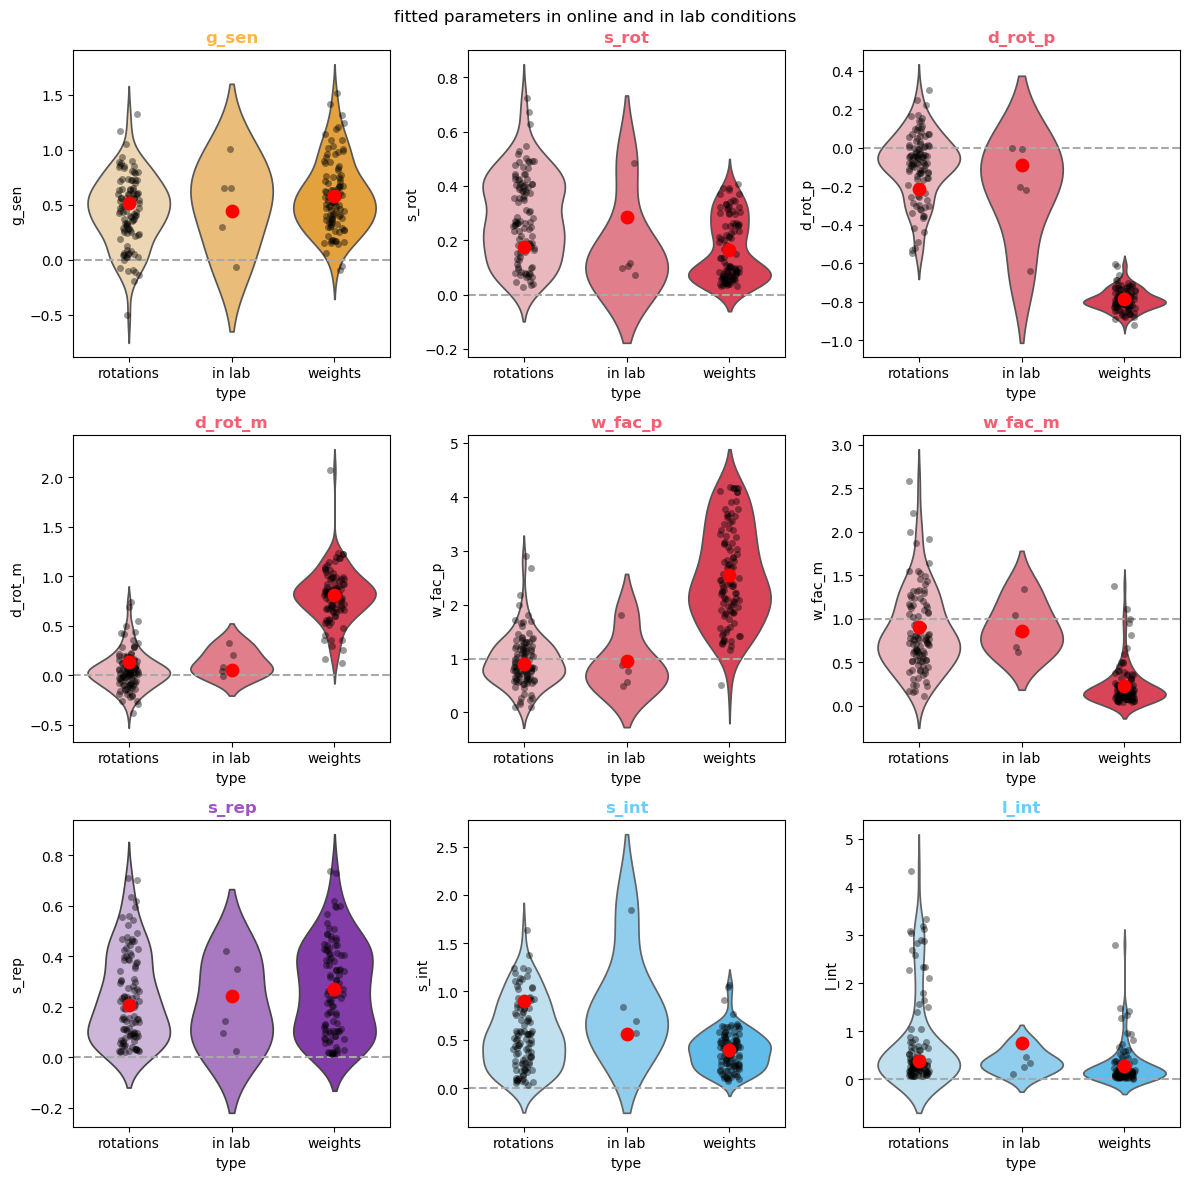

In [186]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": 0,
    "d_rot_m": 0,
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}
positions = [0, 1, 2.3]

for ax, param in zip(axes.flatten(), list(fitted_params_rotations.keys())):

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=80, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()


In [199]:
ref_values = {
    "g_sen": 0,
    "s_rot": 0,
    "d_rot_p": 0,
    "d_rot_m": 0,
    "w_fac_p": 1,
    "w_fac_m": 1,
    "s_int": 0,
    "l_int": 0,
    "s_rep": 0
}

without_rot_weights = ["g_sen", "s_rot", "s_int", "l_int", "s_rep"]
rotation_parameters = ["d_rot_p", "d_rot_m"]
weights_parameters = ["w_fac_p", "w_fac_m"]

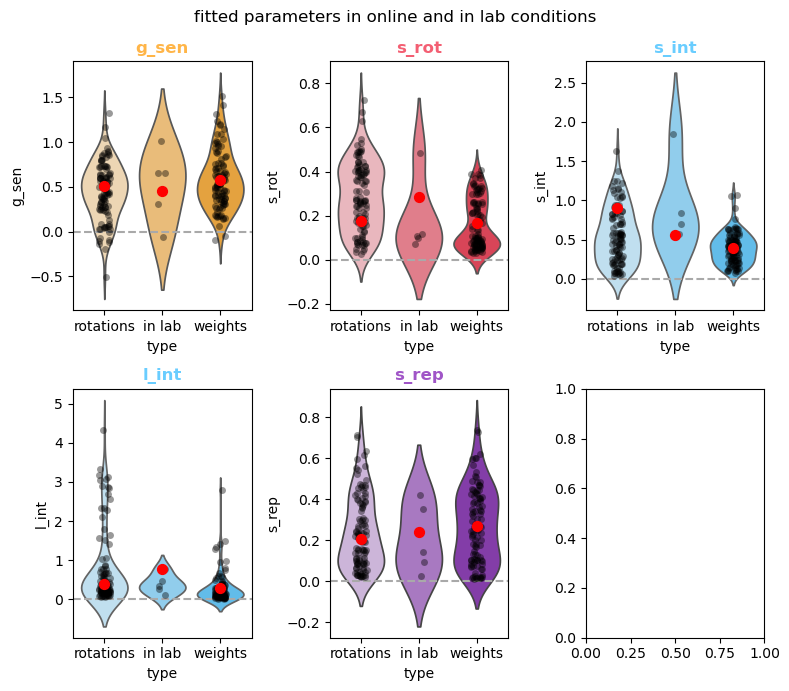

In [205]:
fig, axes = plt.subplots(2, 3, figsize=(8, 7))

for ax, param in zip(axes.flatten(), without_rot_weights) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()


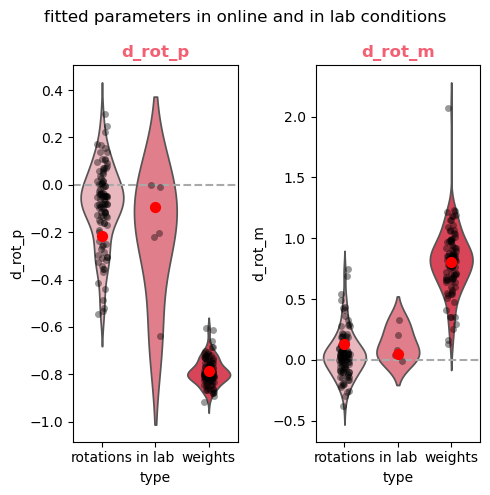

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

for ax, param in zip(axes.flatten(), rotation_parameters) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()


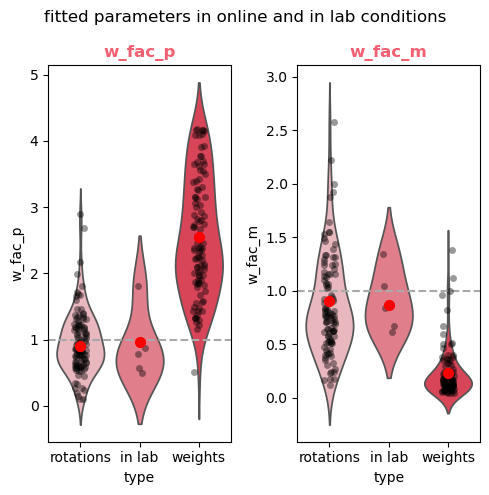

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(5, 5))

for ax, param in zip(axes.flatten(), weights_parameters) :

    data = fitted_params_rotations[param]["average"]
    data2 = fitted_params_inlab[param]["average"]
    data3 = fitted_params_weights[param]["average"]

    df_plot = pd.DataFrame({
        "value": list(data) + list(data2) + list(data3),
        "type": ["rotations"]*len(data) + ["in lab"]*len(data2) + ["weights"]*len(data3)
    })
    category = get_category(param)
    base_color = category_colors[category]

    palette = {
        "rotations": sns.light_palette(base_color, n_colors=4)[1],
        "in lab": sns.light_palette(base_color, n_colors=4)[2],
        "weights": sns.light_palette(base_color, n_colors=4)[3]}

    sns.violinplot(data=df_plot, x="type", y="value", hue = "type", inner=None,
                palette=palette, ax=ax, legend = False)
    

    sns.stripplot(data=df_plot, x="type", y="value",
                color="black", alpha=0.4, ax=ax)

    means = df_plot.groupby("type")["value"].mean()

    for i, (group, m) in enumerate(means.items()):
        ax.scatter(i, m, color="red", s=50, zorder=3, label = f'mean : {m:.2f}')
    
    ref = ref_values[param]
    if ref is not None:
        ax.axhline(ref, color="darkgrey", linestyle="--")
        
    ax.set_ylabel(param)
    ax.set_xticks([])
    ax.set_title(param, color=base_color, fontweight="bold")
    ax.set_xticks([0,1,2])
    ax.set_xticklabels(["rotations", "in lab", "weights"])
    # ax.legend()
    

    
plt.suptitle("fitted parameters in online and in lab conditions")
plt.tight_layout()

# plt.legend()
# plt.savefig("violin plots online vs in lab.pdf")
plt.show()
